<a href="https://colab.research.google.com/github/pratikktiwari/nlp-training/blob/main/GLoVE_Embedding.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import random
import math

random.seed(0)

corpus = [
    'I love computer science',
    'I hate economics',
    'I love music',
    'I hate indoor games',
    'I like reading',
    'I hate rot learning'
]

tokens = []
for sentence in corpus:
    tokens.append(sentence.lower().split())

vocabulary = []
for sentence in tokens:
    for word in sentence:
        if word not in vocabulary:
            vocabulary.append(word)
vocabulary.sort()

word_to_id = {}
id_to_word = {}
for word_id in range(len(vocabulary)):
    word = vocabulary[word_id]
    word_to_id[word] = word_id
    id_to_word[word_id] = word

print(tokens)
print(word_to_id)

[['i', 'love', 'computer', 'science'], ['i', 'hate', 'economics'], ['i', 'love', 'music'], ['i', 'hate', 'indoor', 'games'], ['i', 'like', 'reading'], ['i', 'hate', 'rot', 'learning']]
{'computer': 0, 'economics': 1, 'games': 2, 'hate': 3, 'i': 4, 'indoor': 5, 'learning': 6, 'like': 7, 'love': 8, 'music': 9, 'reading': 10, 'rot': 11, 'science': 12}


In [2]:
window_size = 1

In [3]:
X = []
for word_id in range(len(vocabulary)):
    count_row = []
    for context_id in range(len(vocabulary)):
        count_row.append(0)
    X.append(count_row)

for sentence in tokens:
    for word_position in range(len(sentence)):
        for context_position in range(len(sentence)):
            distance = abs(word_position - context_position)
            if distance > 0 and distance <= window_size:
                word_id = word_to_id[sentence[word_position]]
                context_id = word_to_id[sentence[context_position]]
                X[word_id][context_id] += 1

print('Column order:', vocabulary)
for word_id in range(len(vocabulary)):
    print(id_to_word[word_id], X[word_id])

Column order: ['computer', 'economics', 'games', 'hate', 'i', 'indoor', 'learning', 'like', 'love', 'music', 'reading', 'rot', 'science']
computer [0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1]
economics [0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0]
games [0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0]
hate [0, 1, 0, 0, 3, 1, 0, 0, 0, 0, 0, 1, 0]
i [0, 0, 0, 3, 0, 0, 0, 1, 2, 0, 0, 0, 0]
indoor [0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0]
learning [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0]
like [0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0]
love [1, 0, 0, 0, 2, 0, 0, 0, 0, 1, 0, 0, 0]
music [0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0]
reading [0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0]
rot [0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0]
science [1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [4]:
cooccurrences = []
for word_id in range(len(vocabulary)):
    for context_id in range(len(vocabulary)):
        count = X[word_id][context_id]
        if count > 0:
            cooccurrences.append((word_id, context_id, count))
            print(id_to_word[word_id], '->', id_to_word[context_id],
                  'count:', count, 'log count:', math.log(count))

computer -> love count: 1 log count: 0.0
computer -> science count: 1 log count: 0.0
economics -> hate count: 1 log count: 0.0
games -> indoor count: 1 log count: 0.0
hate -> economics count: 1 log count: 0.0
hate -> i count: 3 log count: 1.0986122886681098
hate -> indoor count: 1 log count: 0.0
hate -> rot count: 1 log count: 0.0
i -> hate count: 3 log count: 1.0986122886681098
i -> like count: 1 log count: 0.0
i -> love count: 2 log count: 0.6931471805599453
indoor -> games count: 1 log count: 0.0
indoor -> hate count: 1 log count: 0.0
learning -> rot count: 1 log count: 0.0
like -> i count: 1 log count: 0.0
like -> reading count: 1 log count: 0.0
love -> computer count: 1 log count: 0.0
love -> i count: 2 log count: 0.6931471805599453
love -> music count: 1 log count: 0.0
music -> love count: 1 log count: 0.0
reading -> like count: 1 log count: 0.0
rot -> hate count: 1 log count: 0.0
rot -> learning count: 1 log count: 0.0
science -> computer count: 1 log count: 0.0


In [5]:
embedding_size = 3
word_vectors = []
context_vectors = []
word_biases = []
context_biases = []

for word_id in range(len(vocabulary)):
    word_vector = []
    context_vector = []
    for dimension in range(embedding_size):
        word_vector.append(random.uniform(-0.1, 0.1))
        context_vector.append(random.uniform(-0.1, 0.1))
    word_vectors.append(word_vector)
    context_vectors.append(context_vector)
    word_biases.append(0.0)
    context_biases.append(0.0)

word_id = word_to_id['i']
context_id = word_to_id['hate']
prediction = word_biases[word_id] + context_biases[context_id]
for dimension in range(embedding_size):
    prediction += word_vectors[word_id][dimension] * context_vectors[context_id][dimension]

print('Initial prediction:', prediction)
print('Target log count:', math.log(X[word_id][context_id]))

Initial prediction: 0.001986189761608336
Target log count: 1.0986122886681098


In [6]:
x_max = 3
alpha = 0.75
learning_rate = 0.05
epochs = 300
loss_history = []

for epoch in range(epochs):
    random.shuffle(cooccurrences)
    total_loss = 0

    for word_id, context_id, count in cooccurrences:
        prediction = word_biases[word_id] + context_biases[context_id]
        for dimension in range(embedding_size):
            prediction += word_vectors[word_id][dimension] * context_vectors[context_id][dimension]

        if count < x_max:
            weight = (count / x_max) ** alpha
        else:
            weight = 1.0

        error = prediction - math.log(count)
        loss = weight * error * error
        total_loss += loss

        bias_gradient = 2 * weight * error
        word_gradient = []
        context_gradient = []
        for dimension in range(embedding_size):
            word_gradient.append(bias_gradient * context_vectors[context_id][dimension])
            context_gradient.append(bias_gradient * word_vectors[word_id][dimension])

        for dimension in range(embedding_size):
            word_vectors[word_id][dimension] -= learning_rate * word_gradient[dimension]
            context_vectors[context_id][dimension] -= learning_rate * context_gradient[dimension]
        word_biases[word_id] -= learning_rate * bias_gradient
        context_biases[context_id] -= learning_rate * bias_gradient

    average_loss = total_loss / len(cooccurrences)
    loss_history.append(average_loss)
    print('Epoch:', epoch + 1, 'Average loss:', average_loss)

Epoch: 1 Average loss: 0.12247852175229046
Epoch: 2 Average loss: 0.07487486172322917
Epoch: 3 Average loss: 0.05076498145186569
Epoch: 4 Average loss: 0.03841961486261516
Epoch: 5 Average loss: 0.03171036209655177
Epoch: 6 Average loss: 0.027850677910059195
Epoch: 7 Average loss: 0.024908659698105438
Epoch: 8 Average loss: 0.023014448517901288
Epoch: 9 Average loss: 0.021330265563261577
Epoch: 10 Average loss: 0.019942079595389146
Epoch: 11 Average loss: 0.018765218923908773
Epoch: 12 Average loss: 0.01767185549420006
Epoch: 13 Average loss: 0.016841414708033364
Epoch: 14 Average loss: 0.01604345844678121
Epoch: 15 Average loss: 0.015215755242297131
Epoch: 16 Average loss: 0.014520891730087327
Epoch: 17 Average loss: 0.01391024028558441
Epoch: 18 Average loss: 0.013274907790012664
Epoch: 19 Average loss: 0.012699687332420296
Epoch: 20 Average loss: 0.012170263527455925
Epoch: 21 Average loss: 0.01162050297272304
Epoch: 22 Average loss: 0.01115871923021112
Epoch: 23 Average loss: 0.010

In [7]:
E = []
for word_id in range(len(vocabulary)):
    embedding = []
    for dimension in range(embedding_size):
        embedding.append(word_vectors[word_id][dimension] + context_vectors[word_id][dimension])
    E.append(embedding)

for word_id in range(len(vocabulary)):
    print(id_to_word[word_id], E[word_id])

computer [0.12409166170505988, -0.07414073514018343, -0.0027733624367655913]
economics [-0.019286468320959347, 0.004560924711623202, -0.0006401948575369548]
games [0.01225465623013991, -0.0298506696841625, 0.14871476019667734]
hate [0.18711457808400833, 0.030333998869880544, 0.7192000857967066]
i [0.11106001692460254, -0.00681290871161272, 0.7864816548468937]
indoor [0.004595852268544129, -0.010040295835467991, -0.22023753876552352]
learning [0.016657533608421007, 0.09461632566693391, -0.1432920833697128]
like [0.004922419939609457, 0.09761079402270445, -0.47027121506543546]
love [-0.0022890133185901745, 0.06400932110491936, -0.07193194662494057]
music [0.08885758400320966, -0.07133602823951432, 0.05533752641667069]
reading [0.07155687293990283, 0.14925357565683167, -0.10451309320114344]
rot [-0.062050208319835855, -0.020658565615138083, -0.30420920866523427]
science [0.05926552564283914, -0.0902266423115275, 0.12632443674806598]


In [8]:
def cosine_similarity(vector_a, vector_b):
    dot_product = 0
    squared_length_a = 0
    squared_length_b = 0
    for dimension in range(len(vector_a)):
        dot_product += vector_a[dimension] * vector_b[dimension]
        squared_length_a += vector_a[dimension] * vector_a[dimension]
        squared_length_b += vector_b[dimension] * vector_b[dimension]

    length_a = math.sqrt(squared_length_a)
    length_b = math.sqrt(squared_length_b)
    return dot_product / (length_a * length_b + 1e-12)


def similar_words(word, top_k=3):
    word_id = word_to_id[word]
    similarities = []
    for other_id in range(len(vocabulary)):
        if other_id != word_id:
            similarity = cosine_similarity(E[word_id], E[other_id])
            similarities.append((id_to_word[other_id], similarity))

    similarities.sort(key=lambda item: item[1], reverse=True)
    return similarities[:top_k]


print('Words similar to love:', similar_words('love'))
print('Words similar to hate:', similar_words('hate'))

Words similar to love: [('learning', 0.9825100234407879), ('reading', 0.8967581482094804), ('like', 0.8660267441072267)]
Words similar to hate: [('i', 0.99226830669748), ('games', 0.9572469477704274), ('science', 0.8027093178964241)]


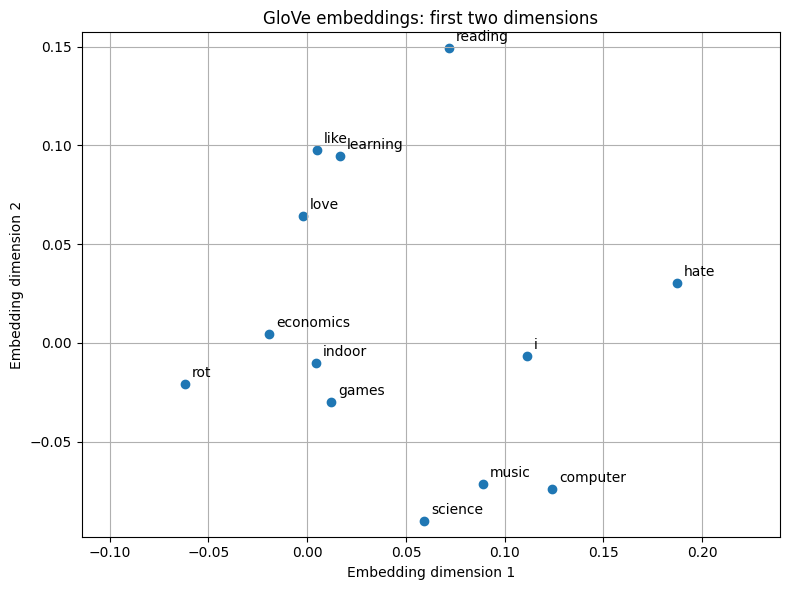

In [9]:
import matplotlib.pyplot as plt

if embedding_size < 2:
    raise ValueError('The plot needs at least two embedding dimensions.')

x_coordinates = []
y_coordinates = []
for word_id in range(len(vocabulary)):
    x_coordinates.append(E[word_id][0])
    y_coordinates.append(E[word_id][1])

plt.figure(figsize=(8, 6))
plt.scatter(x_coordinates, y_coordinates)
for word_id in range(len(vocabulary)):
    plt.annotate(id_to_word[word_id],
                 (x_coordinates[word_id], y_coordinates[word_id]),
                 xytext=(5, 5), textcoords='offset points')

plt.xlabel('Embedding dimension 1')
plt.ylabel('Embedding dimension 2')
plt.title('GloVe embeddings: first two dimensions')
plt.axis('equal')
plt.grid(True)
plt.tight_layout()
plt.show()